# Scale latitudinal gradient EOFs

## Imports

In [1]:
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openscm_units
import pandas as pd
import pandas_indexing as pix  # noqa: F401
import pandas_openscm
import pint
import pint_xarray
import seaborn as sns
import xarray as xr

from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation import (
    LaiKaplanInterpolator,
    interpolate_annual_mean_to_monthly,
)
from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation.lai_kaplan import (
    get_wall_control_points_y_cubic,
)

## Parameters

In [2]:
ghg: str = "ch4"
annual_mean_emissions_file: str = (
    "../output-bundles/dev-test/data/interim/single-variable-files/ch4_eof-one-scaling.feather"
)
harmonisation_year: int = 2015
historical_data_root_dir: str = "../output-bundles/dev-test/data/raw/historical-ghg-concs"
historical_data_seasonality_lat_gradient_info_root: str = (
    "../output-bundles/dev-test/data/raw/historical-ghg-data-interim"
)
out_file: str = "../output-bundles/dev-test/data/interim/latitudinal-gradient/ch4_latitudinal-gradient-info.nc"

In [3]:
# Parameters
ghg = "co2"
annual_mean_emissions_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/single-variable-files/co2_eof-one-scaling.feather"
harmonisation_year = 2015
historical_data_root_dir = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/raw/historical-ghg-concs"
historical_data_seasonality_lat_gradient_info_root = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/raw/historical-ghg-data-interim"
out_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/latitudinal-gradient/co2_latitudinal-gradient-info.nc"


## Parse parameters

In [4]:
annual_mean_emissions_file_p = Path(annual_mean_emissions_file)
historical_data_root_dir_p = Path(historical_data_root_dir)
historical_data_seasonality_lat_gradient_info_root_p = Path(historical_data_seasonality_lat_gradient_info_root)
out_file_p = Path(out_file)

## Set up

In [5]:
ur = pint_xarray.setup_registry(openscm_units.unit_registry)
Q = ur.Quantity
pandas_openscm.register_pandas_accessor()

## Load data

### Annual-mean emissions

In [6]:
annual_mean_emissions = pd.read_feather(annual_mean_emissions_file_p)
ghg_search_for = ghg

annual_mean_emissions_emms_units = annual_mean_emissions.loc[
    annual_mean_emissions.index.get_level_values("unit").str.lower().str.contains(ghg_search_for)
]
if len(annual_mean_emissions_emms_units.pix.unique("unit")) != 1:
    raise AssertionError

annual_mean_emissions_emms_u = annual_mean_emissions_emms_units.pix.unique("unit")[0]

annual_mean_emissions_emms_units

,,year,1750,1751,1752,1753,1754,1755,1756,1757,1758,1759,...,2491,2492,2493,2494,2495,2496,2497,2498,2499,2500
unit,scenario,variable,,,,,,,,,,,,,,,,,,,,,
Mt CO2/yr,vl-cf,Emissions|CO2|Fossil,8.734585,8.734585,8.738008,8.738008,8.74143,8.744853,9.347238,9.350661,9.354083,9.357506,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
# Take any scenario, doesn't matter as all the same pre-harmonisation
annual_mean_emissions_emms_units_historical = annual_mean_emissions_emms_units.loc[:, :harmonisation_year].iloc[:1, :]
annual_mean_emissions_emms_units_historical

,,year,1750,1751,1752,1753,1754,1755,1756,1757,1758,1759,...,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
unit,scenario,variable,,,,,,,,,,,,,,,,,,,,,
Mt CO2/yr,vl-cf,Emissions|CO2|Fossil,8.734585,8.734585,8.738008,8.738008,8.74143,8.744853,9.347238,9.350661,9.354083,9.357506,...,31160.440242,32343.598801,32576.677637,31859.502609,33788.54967,34768.01705,35167.694337,35820.08431,36098.75542,36013.858719


### CMIP7 historical GHG concentrations

In [8]:
def load_file_from_glob(glob: str, base_dir: Path) -> xr.Dataset:
    """
    Load a single file based on a glob pattern
    """
    file_l = list(base_dir.rglob(glob))
    if len(file_l) != 1:
        raise AssertionError(file_l)

    ds = xr.load_dataset(file_l[0])

    return ds

In [9]:
cmip7_historical_gm_monthly_ds = load_file_from_glob(f"*{ghg}_*gm_175001-*.nc", historical_data_root_dir_p)
cmip7_historical_gm_monthly = cmip7_historical_gm_monthly_ds[ghg]
# cmip7_historical_gm_monthly

### CMIP7 historical latitudinal gradient

In [10]:
cmip7_lat_gradient_pieces_ds = load_file_from_glob(
    f"{ghg}_allyears-lat-gradient-eofs-pcs.nc", historical_data_seasonality_lat_gradient_info_root_p
).pint.quantify(unit_registry=ur)
# cmip7_lat_gradient_pieces_ds

## Regress emissions against PC0

In [11]:
pc0 = cmip7_lat_gradient_pieces_ds["principal-components"].sel(eof=0)
start_non_constant_pc0 = np.where(pc0.diff("year") != 0.0)[0][0]
start_non_constant_pc0

1749

In [12]:
annual_mean_emissions_emms_non_zero_years = (
    annual_mean_emissions_emms_units_historical[annual_mean_emissions_emms_units_historical > 0.0]
    .dropna(axis="columns")
    .columns
)
annual_mean_emissions_emms_non_zero_years

Index([1750, 1751, 1752, 1753, 1754, 1755, 1756, 1757, 1758, 1759,
       ...
       2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015],
      dtype='int64', name='year', length=266)

In [13]:
regression_years = np.intersect1d(
    pc0.sel(year=pc0["year"] >= start_non_constant_pc0)["year"].values,
    annual_mean_emissions_emms_non_zero_years,
)
regression_years

array([1750, 1751, 1752, 1753, 1754, 1755, 1756, 1757, 1758, 1759, 1760,
       1761, 1762, 1763, 1764, 1765, 1766, 1767, 1768, 1769, 1770, 1771,
       1772, 1773, 1774, 1775, 1776, 1777, 1778, 1779, 1780, 1781, 1782,
       1783, 1784, 1785, 1786, 1787, 1788, 1789, 1790, 1791, 1792, 1793,
       1794, 1795, 1796, 1797, 1798, 1799, 1800, 1801, 1802, 1803, 1804,
       1805, 1806, 1807, 1808, 1809, 1810, 1811, 1812, 1813, 1814, 1815,
       1816, 1817, 1818, 1819, 1820, 1821, 1822, 1823, 1824, 1825, 1826,
       1827, 1828, 1829, 1830, 1831, 1832, 1833, 1834, 1835, 1836, 1837,
       1838, 1839, 1840, 1841, 1842, 1843, 1844, 1845, 1846, 1847, 1848,
       1849, 1850, 1851, 1852, 1853, 1854, 1855, 1856, 1857, 1858, 1859,
       1860, 1861, 1862, 1863, 1864, 1865, 1866, 1867, 1868, 1869, 1870,
       1871, 1872, 1873, 1874, 1875, 1876, 1877, 1878, 1879, 1880, 1881,
       1882, 1883, 1884, 1885, 1886, 1887, 1888, 1889, 1890, 1891, 1892,
       1893, 1894, 1895, 1896, 1897, 1898, 1899, 19

In [14]:
pc0_to_regress = pc0.sel(year=regression_years)
# pc0_to_regress

In [15]:
annual_mean_emissions_emms_units_historical_to_regress_q = Q(
    annual_mean_emissions_emms_units_historical.loc[:, regression_years].values.squeeze(), annual_mean_emissions_emms_u
)
# annual_mean_emissions_emms_units_historical_to_regress_q

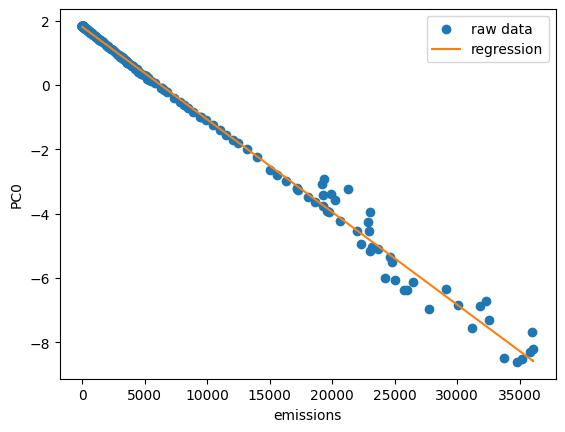

In [16]:
x = annual_mean_emissions_emms_units_historical_to_regress_q
A = np.vstack([x.m, np.ones(x.size)]).T
y = pc0_to_regress.data

res = np.linalg.lstsq(A, y.m, rcond=None)
m, c = res[0]
m = Q(m, (y / x).units)
# c = Q(c, y.units)

fig, ax = plt.subplots()
ax.scatter(x.m, y.m, label="raw data")
ax.plot(x.m, (m * x + c).m, color="tab:orange", label="regression")
ax.set_ylabel("PC0")
ax.set_xlabel("emissions")
ax.legend()

## Scale latitudinal gradient PCs

### PC0

In [17]:
# So ugly.
# Basically, we need to keep things consistent
# at the join point.
# For ScenarioMIP, that's 2022: we want everything the same in 2022.
# For PolMIP, that's 2015: we want everything the same in 2015,
# divergence thereafter.
last_hist_year = min(
    cmip7_historical_gm_monthly["time"].dt.year.values[-1],
    harmonisation_year,
)
last_hist_year

2015

In [18]:
delta_E = (
    annual_mean_emissions_emms_units.loc[:, last_hist_year:].subtract(
        annual_mean_emissions_emms_units[last_hist_year], axis="rows"
    )
).pix.assign(variable="change_in_emissions")
delta_E

,,year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,...,2491,2492,2493,2494,2495,2496,2497,2498,2499,2500
unit,scenario,variable,,,,,,,,,,,,,,,,,,,,,
Mt CO2/yr,vl-cf,change_in_emissions,0.0,-722.872366,-1442.916748,-2160.133147,-2874.521563,-3586.081994,-5804.244196,-8043.098449,-10302.644753,-12582.883108,...,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719,-36013.858719


In [19]:
delta_E_unit_l = delta_E.pix.unique("unit")
if len(delta_E_unit_l) != 1:
    raise AssertionError(delta_E_unit_l)

delta_E_unit = delta_E_unit_l[0]

delta_E_xr = xr.DataArray(
    delta_E.values,
    dims=["scenario", "year"],
    coords=dict(scenario=delta_E.index.get_level_values("scenario"), year=delta_E.columns),
).pint.quantify(delta_E_unit, unit_registry=ur)
# delta_E_xr

In [20]:
delta_pc = delta_E_xr * m
# delta_pc

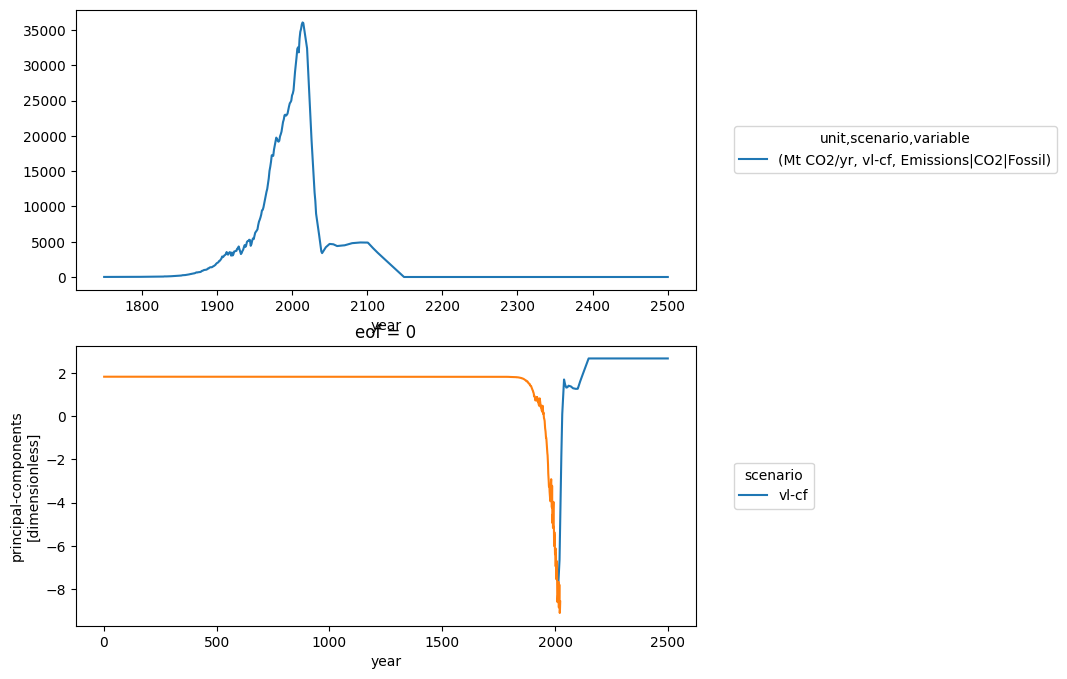

In [21]:
pc0_extended = delta_pc + pc0.sel(year=last_hist_year)

fig, axes = plt.subplots(nrows=2, figsize=(8, 8))
annual_mean_emissions_emms_units.T.plot(ax=axes[0])
pc0_extended.pint.to("dimensionless").plot(ax=axes[1], hue="scenario")
pc0.pint.to("dimensionless").plot(ax=axes[1])
for ax in axes:
    sns.move_legend(ax, loc="center left", bbox_to_anchor=(1.05, 0.5))

# pc0_extended

### PC1

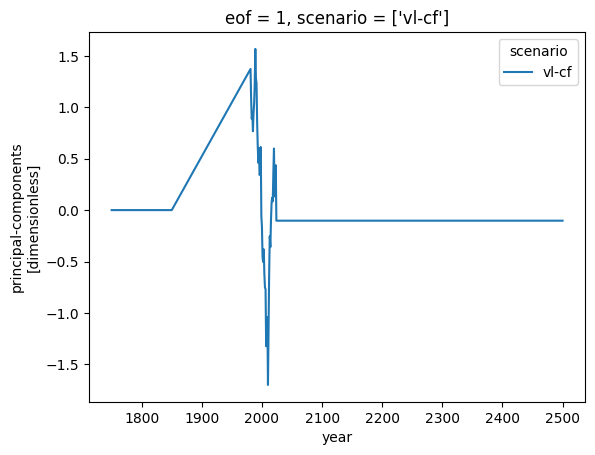

In [22]:
pc1 = cmip7_lat_gradient_pieces_ds["principal-components"].sel(eof=1)
pc1_extended = pc1.pint.dequantify().interp(
    year=annual_mean_emissions.columns, kwargs={"fill_value": pc1.sel(year=last_hist_year).data.m}
)

pc1_extended_all_scenarios_l = []
for scenario in pc0_extended["scenario"]:
    pc1_extended_all_scenarios_l.append(pc1_extended.assign_coords(scenario=scenario.data))

pc1_extended_all_scenarios = xr.concat(pc1_extended_all_scenarios_l, dim="scenario")
pc1_extended_all_scenarios

pc1_extended_all_scenarios.plot(hue="scenario")

pc1_extended_all_scenarios = pc1_extended_all_scenarios.sel(
    year=annual_mean_emissions.loc[:, last_hist_year:].columns
).pint.quantify(unit_registry=ur)

# pc1_extended_all_scenarios

In [23]:
exp_n_eofs = 2
if cmip7_lat_gradient_pieces_ds["eof"].size != exp_n_eofs:
    raise AssertionError

## Interpolate to monthly

We have to ensure that the scenarios stay harmonised until the last month of the historical data.
Therefore, we use the same wall control point value for all scenarios.
As a simple choice, we use the average wall control point across all scenarios.

In [24]:
def get_wall_control_points(
    intervals_x: pint.UnitRegistry.Quantity,
    intervals_y: pint.UnitRegistry.Quantity,
    control_points_wall_x: pint.UnitRegistry.Quantity,
    fixed_control_point: pint.UnitRegistry.Quantity,
) -> pint.UnitRegistry.Quantity:
    """
    Get wall control points including setting our fixed control point
    """
    # Start off with standard implementation
    control_points_wall_y = get_wall_control_points_y_cubic(
        intervals_x=intervals_x,
        intervals_y=intervals_y,
        control_points_wall_x=control_points_wall_x,
    )

    # Also fix the control point between overlap year month 12 and overlap year + 1 month 1
    fixed_control_point_idxr = np.where(
        control_points_wall_x == openscm_units.unit_registry.Quantity(last_hist_year + 1, "yr")
    )
    control_points_wall_y[fixed_control_point_idxr] = fixed_control_point

    return control_points_wall_y

In [25]:
pcs_extended_monthly_l = []
for pc_extended in [
    pc0_extended,
    pc1_extended_all_scenarios,
]:
    tmp_l = []
    fixed_control_point = (
        pc_extended.sel(year=[last_hist_year, last_hist_year + 1]).mean("year").mean("scenario").data.squeeze()
    )

    for scenario, sda in pc_extended.groupby("scenario"):
        scenario_monthly = interpolate_annual_mean_to_monthly(
            values=sda.data.m.squeeze(),
            values_units=pc_extended.data.u,
            years=pc_extended["year"].values,
            algorithm=LaiKaplanInterpolator(
                progress_bar=True,
                get_wall_control_points_y_from_interval_ys=partial(
                    get_wall_control_points, fixed_control_point=fixed_control_point
                ),
            ),
            unit_registry=openscm_units.unit_registry,
        ).assign_coords(scenario=scenario, eof=pc_extended["eof"].values)
        tmp_l.append(scenario_monthly)

    pcs_extended_monthly_l.append(xr.concat(tmp_l, dim="scenario"))

pcs_extended_monthly = xr.concat(pcs_extended_monthly_l, dim="eof")
pcs_extended_monthly.name = "principal-components-monthly"
pcs_extended_monthly.attrs["description"] = "principal component values on a monthly timestep"
pcs_extended_monthly

Calculating output values:   0%|          | 0/5832 [00:00<?, ?it/s]

Calculating output values:   0%|          | 0/5832 [00:00<?, ?it/s]

Magnitude,[[[-7.732758845842548 -7.733452742415303 -7.732632911833779 ... 2.6836428875064473 2.683642887506447 2.6836428875064473]] [[-0.14629009239818053 -0.14520784107985196 -0.1420444738554226 ... -0.10292169544148293 -0.10292169544148307 -0.10292169544148297]]]
Units,dimensionless


In [26]:
months_per_year = 12

for _, pc_extended_monthly in pcs_extended_monthly.groupby("eof"):
    last_overlap_month = pc_extended_monthly.sel(
        time=(pc_extended_monthly["time"].dt.year == last_hist_year)
        & (pc_extended_monthly["time"].dt.month == months_per_year)
    )

    np.testing.assert_allclose(
        last_overlap_month.data.m.squeeze(),
        last_overlap_month.data.m[0].squeeze(),
        rtol=1e-3,
    )

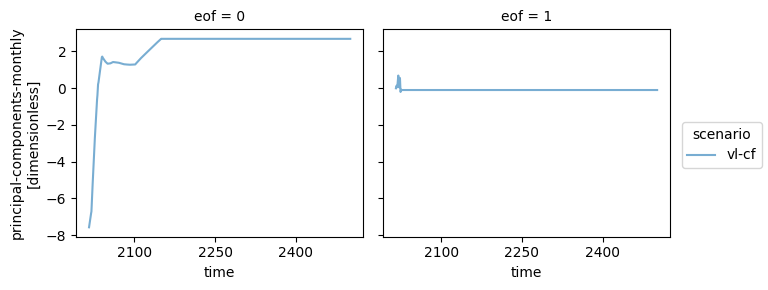

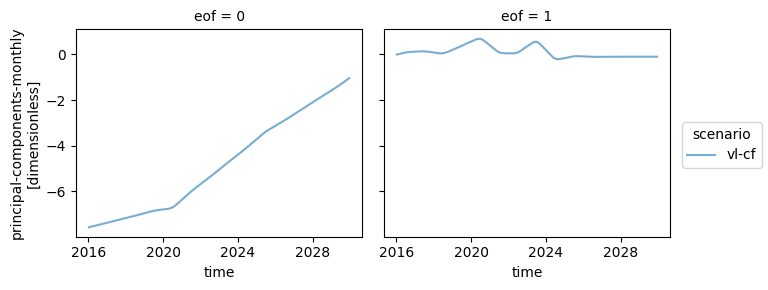

In [27]:
for years in (
    np.arange(last_hist_year + 1, 2500 + 1),
    np.arange(last_hist_year + 1, last_hist_year + 15),
):
    pcs_extended_monthly.sel(time=pcs_extended_monthly["time"].dt.year.isin(years)).pint.to("dimensionless").plot(
        alpha=0.6,
        hue="scenario",
        col="eof",
    )

    plt.show()

## Prepare output

In [28]:
eofs = cmip7_lat_gradient_pieces_ds["eofs"]

out = xr.merge(
    [
        eofs,
        pcs_extended_monthly.pint.to("dimensionless"),
    ],
    combine_attrs="drop_conflicts",
).pint.dequantify()

out

<xarray.Dataset> Size: 140kB
Dimensions:                       (lat: 12, eof: 2, scenario: 1, time: 5832)
Coordinates:
  * eof                           (eof) int64 16B 0 1
  * lat                           (lat) float64 96B -82.5 -67.5 ... 67.5 82.5
  * time                          (time) object 47kB 2015-01-15 00:00:00 ... ...
  * scenario                      (scenario) <U5 20B 'vl-cf'
Data variables:
    eofs                          (lat, eof) float64 192B 0.3399 ... 0.4281
    principal-components-monthly  (eof, scenario, time) float64 93kB -7.733 ....

In [29]:
# Double check this can work
out_tmp = out.pint.quantify(unit_registry=ur)
tmp = (out_tmp["eofs"] * out_tmp["principal-components-monthly"]).sum("eof")
# tmp

## Save

In [30]:
out_file_p.parent.mkdir(exist_ok=True, parents=True)
out.to_netcdf(out_file_p)
out_file_p

PosixPath('/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/latitudinal-gradient/co2_latitudinal-gradient-info.nc')